In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
import seaborn as sns


In [2]:
df=pd.read_csv('Adult Census Income.csv')

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(24)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [7]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [8]:
df.shape

(32561, 15)

In [9]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='str')

In [10]:
df = df.replace('?', np.nan)

In [11]:
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

In [12]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

In [13]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [14]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


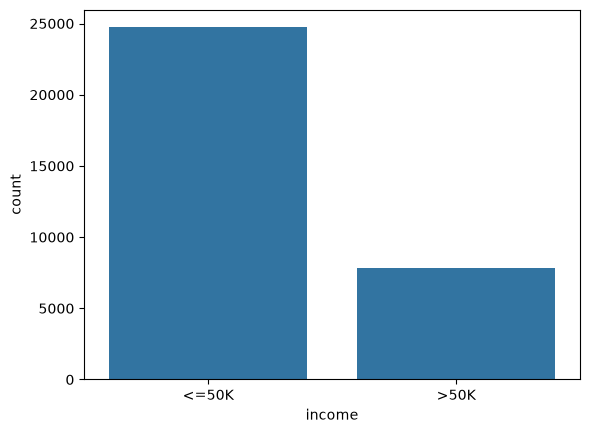

In [15]:
sns.countplot(data=df, x="income")
plt.show()

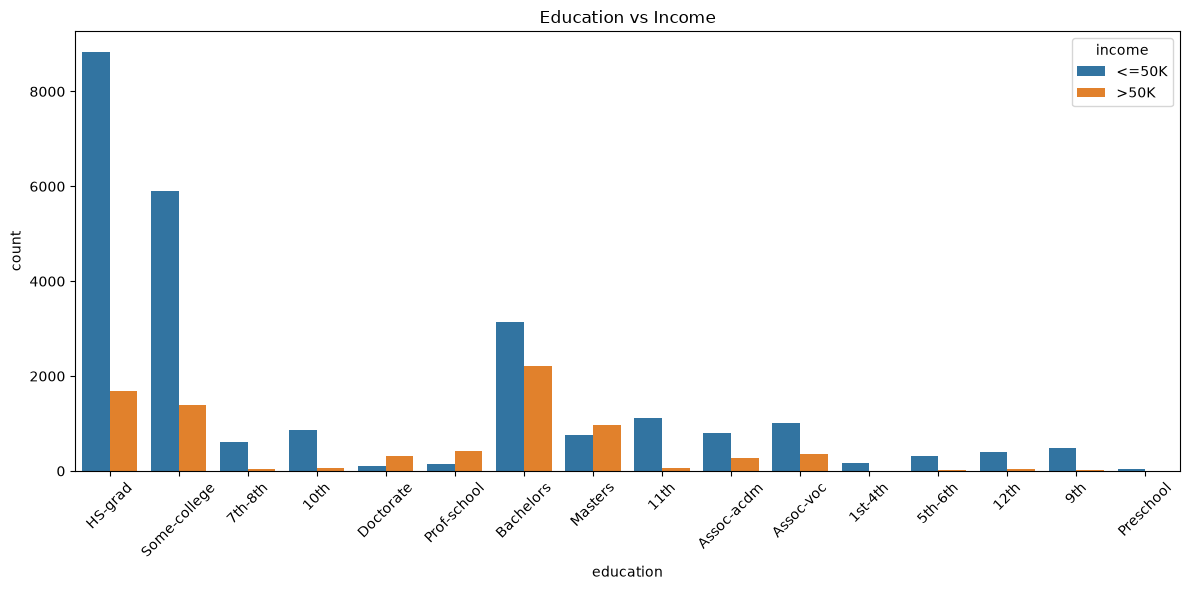

In [16]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="education", hue="income")
plt.xticks(rotation=45)
plt.title("Education vs Income")
plt.tight_layout()
plt.show()

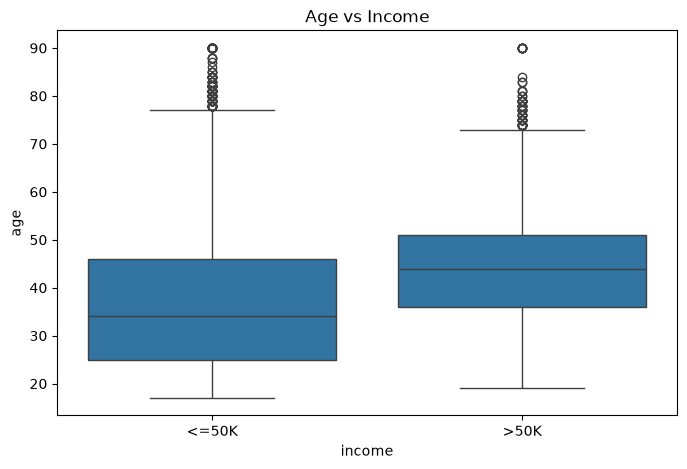

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="income", y="age")
plt.title("Age vs Income")
plt.show()

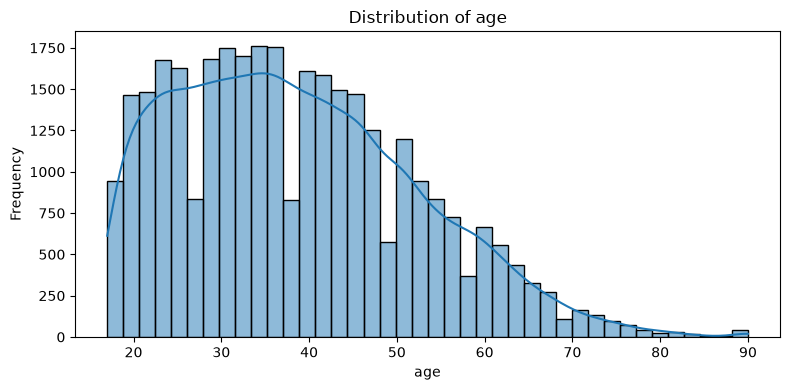

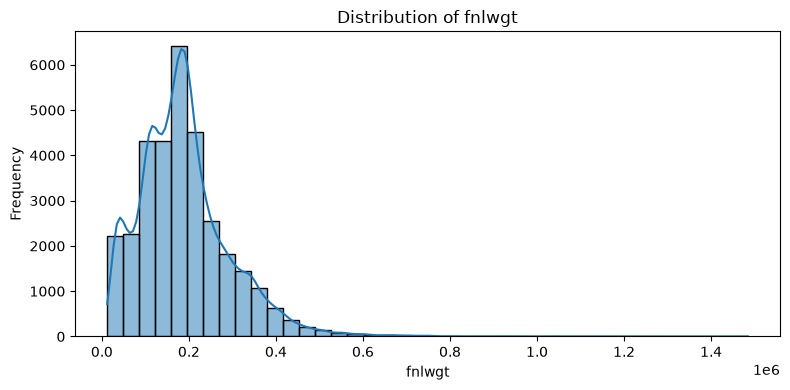

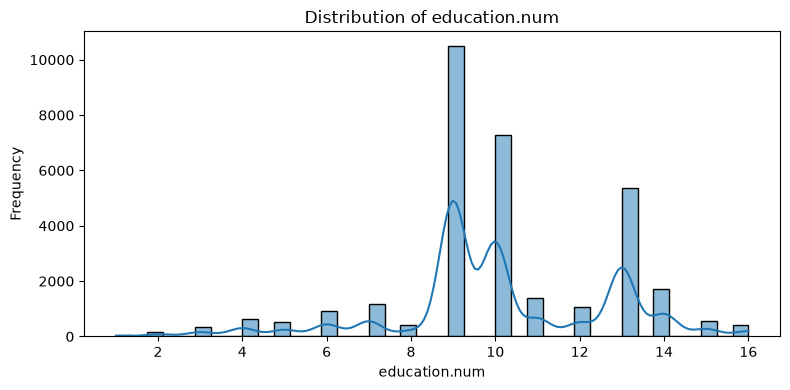

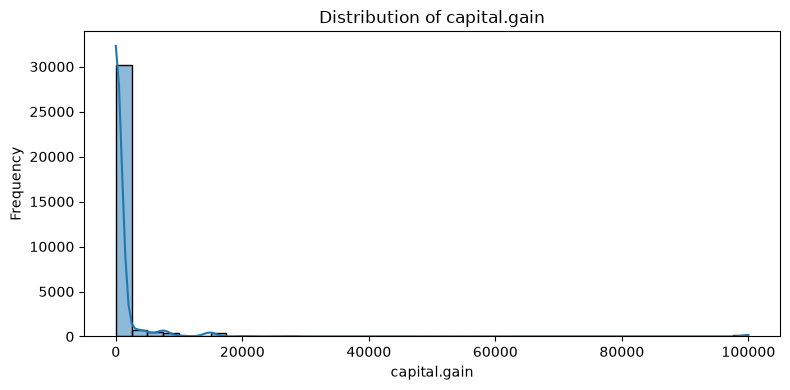

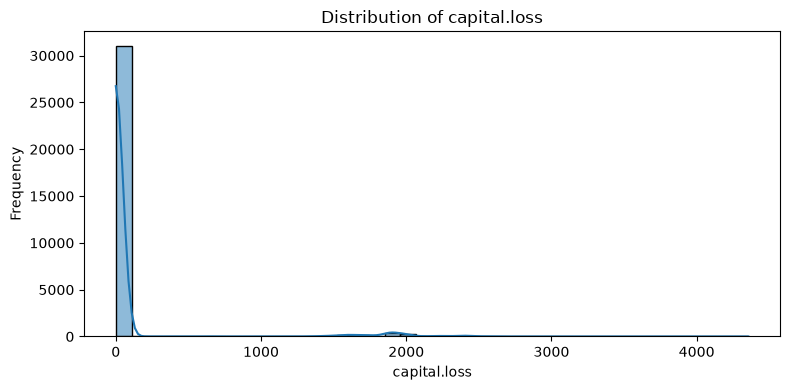

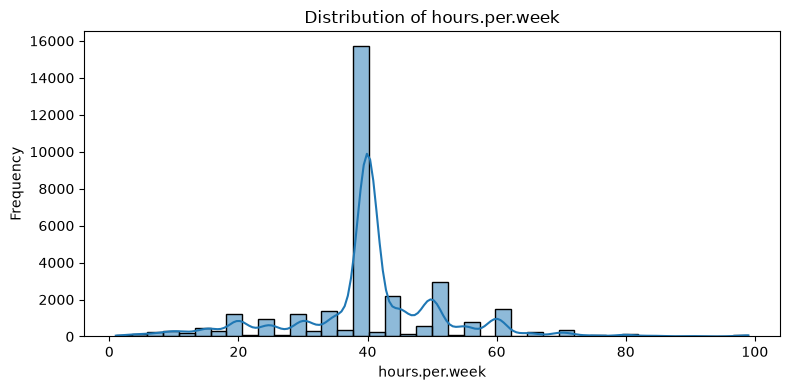

In [18]:
numeric_cols = ["age","fnlwgt","education.num","capital.gain","capital.loss","hours.per.week"]
for column in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=column, kde=True, bins=40)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [19]:
for column in numeric_cols:
    print(column, ":", round(df[column].skew(), 3))

age : 0.559
fnlwgt : 1.447
education.num : -0.312
capital.gain : 11.954
capital.loss : 4.595
hours.per.week : 0.228


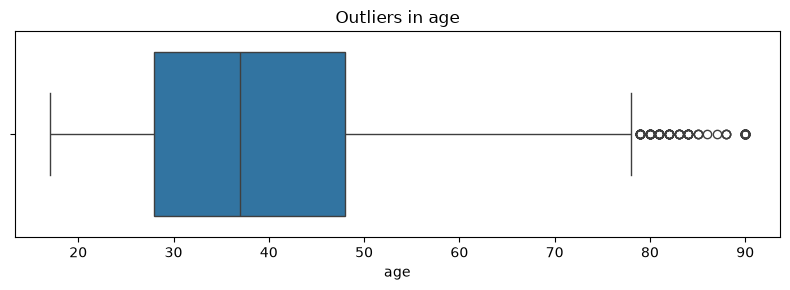

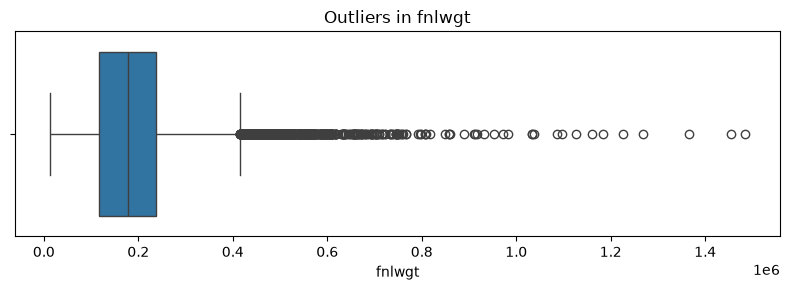

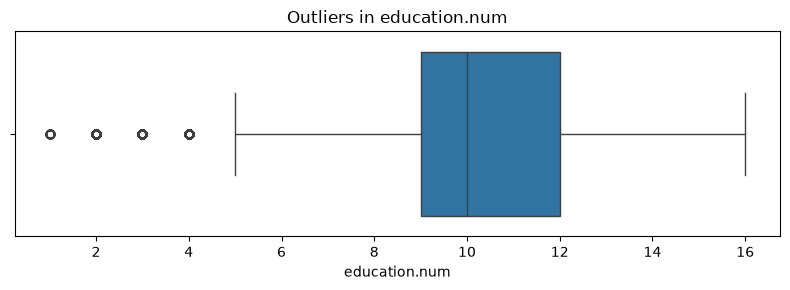

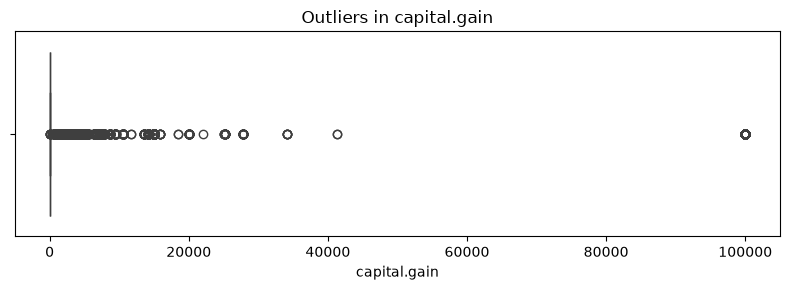

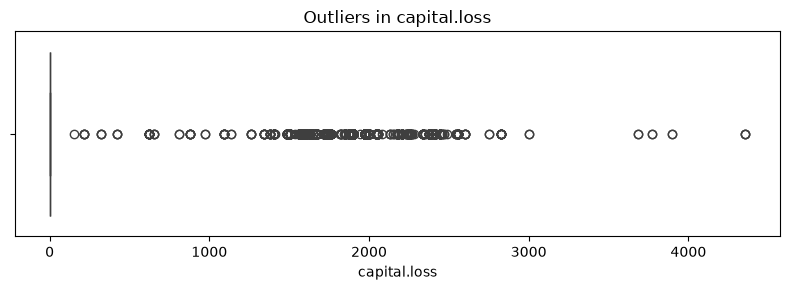

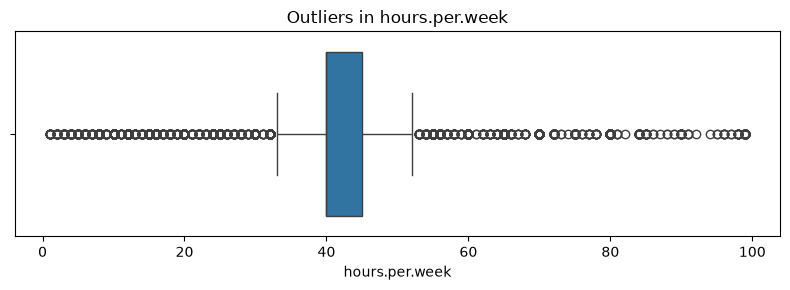

In [20]:
for column in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=df, x=column)
    plt.title(f"Outliers in {column}")
    plt.tight_layout()
    plt.show()

In [21]:
for column in numeric_cols:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outliers Count:", len(outliers))
    print("Outliers Percentage:", round(len(outliers) / len(df) * 100, 2), "%")


age
Lower Bound: -2.0
Upper Bound: 78.0
Outliers Count: 143
Outliers Percentage: 0.44 %

fnlwgt
Lower Bound: -61009.0
Upper Bound: 415887.0
Outliers Count: 992
Outliers Percentage: 3.05 %

education.num
Lower Bound: 4.5
Upper Bound: 16.5
Outliers Count: 1198
Outliers Percentage: 3.68 %

capital.gain
Lower Bound: 0.0
Upper Bound: 0.0
Outliers Count: 2712
Outliers Percentage: 8.33 %

capital.loss
Lower Bound: 0.0
Upper Bound: 0.0
Outliers Count: 1519
Outliers Percentage: 4.67 %

hours.per.week
Lower Bound: 32.5
Upper Bound: 52.5
Outliers Count: 9008
Outliers Percentage: 27.66 %


In [22]:
df["capital.gain"] = pd.to_numeric(
    df["capital.gain"], errors="coerce"
)
df["capital.loss"] = pd.to_numeric(
    df["capital.loss"], errors="coerce"
)
df["fnlwgt"] = pd.to_numeric(
    df["fnlwgt"], errors="coerce"
)

In [23]:
Q1 = df["fnlwgt"].quantile(0.25)
Q3 = df["fnlwgt"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df["fnlwgt"] = df["fnlwgt"].clip(
    lower=lower_bound,
    upper=upper_bound
)

# 2. Log transformation for highly skewed columns
df["capital.gain"] = np.log1p(df["capital.gain"])
df["capital.loss"] = np.log1p(df["capital.loss"])
df["fnlwgt"] = np.log1p(df["fnlwgt"])

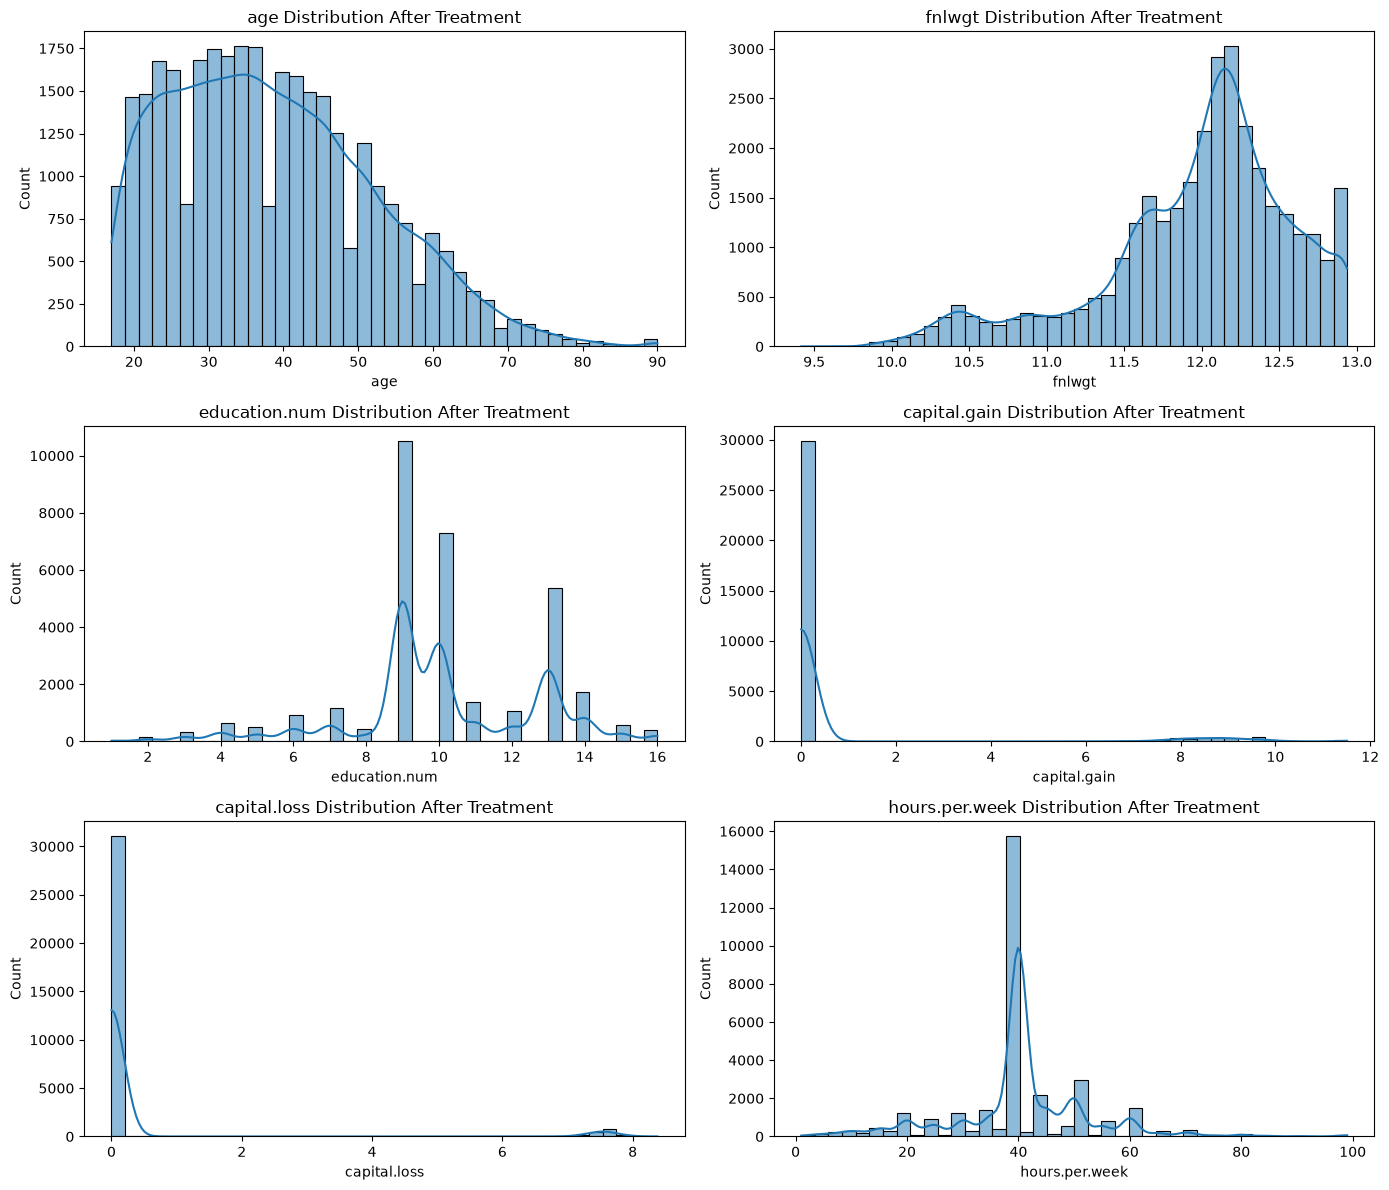

In [24]:
columns = [
    "age",
    "fnlwgt",
    "education.num",
    "capital.gain",
    "capital.loss",
    "hours.per.week"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, column in enumerate(columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=40,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"{column} Distribution After Treatment"
    )

plt.tight_layout()
plt.show()

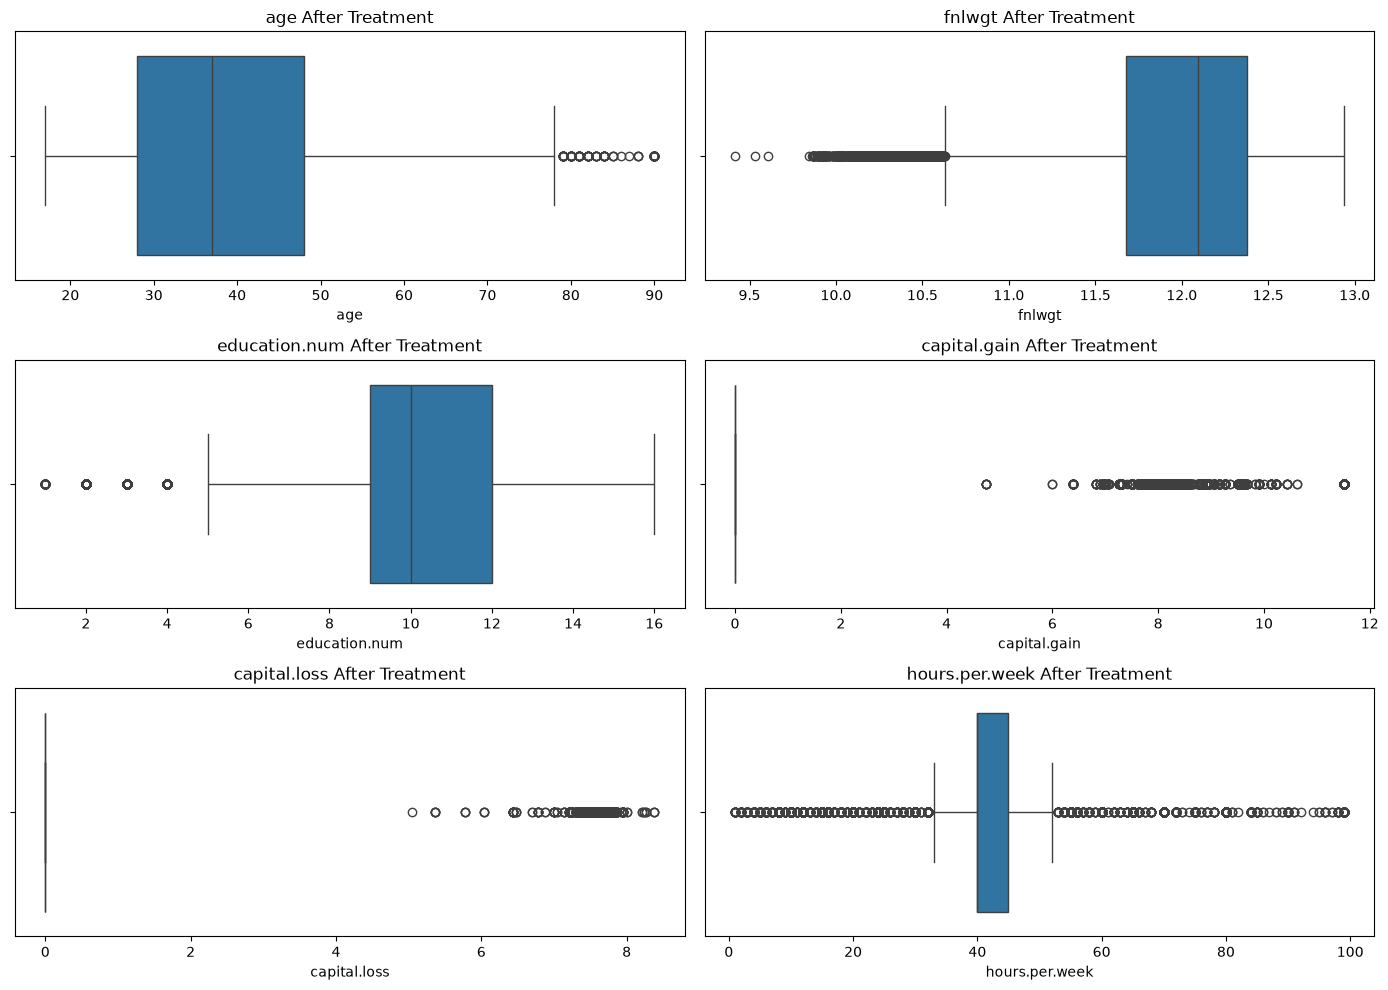

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for i, column in enumerate(columns):
    sns.boxplot(
        data=df,
        x=column,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"{column} After Treatment"
    )

plt.tight_layout()
plt.show()

In [26]:
for column in numeric_cols:
    print(
        column,
        round(df[column].skew(), 3)
    )

age 0.559
fnlwgt -0.956
education.num -0.312
capital.gain 3.096
capital.loss 4.308
hours.per.week 0.228


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Prepare target
df["income"] = df["income"].str.strip()

y = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

# Check target mapping
if y.isna().any():
    raise ValueError("Check the values in the income column")

# 2. Drop redundant education column
X = df.drop(columns=["income", "education"]).copy()

# 3. Binary encoding for sex
X["sex"] = X["sex"].str.strip().map({
    "Female": 0,
    "Male": 1
})

if X["sex"].isna().any():
    raise ValueError("Check the values in the sex column")

# 4. Define categorical columns
categorical_cols = [
    "workclass",
    "marital.status",
    "occupation",
    "relationship",
    "race",
    "native.country"
]

# 5. Split before fitting the encoder
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 6. Apply One-Hot Encoding
encoder = ColumnTransformer(
    transformers=[
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

X_train = encoder.fit_transform(X_train)
X_test = encoder.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (26048, 87)
X_test shape: (6513, 87)
y_train shape: (26048,)
y_test shape: (6513,)


In [28]:
from sklearn.preprocessing import StandardScaler
from scipy.sparse import issparse
# Convert sparse matrices to dense arrays
if issparse(X_train):
    X_train = X_train.toarray()

if issparse(X_test):
    X_test = X_test.toarray()

# Get encoded feature names
feature_names = encoder.get_feature_names_out()

# Identify numeric columns that need scaling
numeric_cols = [
    "age",
    "fnlwgt",
    "education.num",
    "capital.gain",
    "capital.loss",
    "hours.per.week"
]

numeric_indices = [
    list(feature_names).index(col)
    for col in numeric_cols
]

# Scale numerical features only
scaler = StandardScaler()

X_train[:, numeric_indices] = scaler.fit_transform(
    X_train[:, numeric_indices]
)

X_test[:, numeric_indices] = scaler.transform(
    X_test[:, numeric_indices]
)

print("Scaling completed!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Scaling completed!
X_train shape: (26048, 87)
X_test shape: (6513, 87)


In [29]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

print("\nBalanced X_train shape:", X_train_balanced.shape)
print("X_test shape:", X_test.shape)

Before SMOTE:
income
0    19775
1     6273
Name: count, dtype: int64

After SMOTE:
income
1    19775
0    19775
Name: count, dtype: int64

Balanced X_train shape: (39550, 87)
X_test shape: (6513, 87)


In [30]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000,random_state=42),
    "KNN Classifier": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)


Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.94      0.79      0.86      4945
        >50K       0.56      0.83      0.67      1568

    accuracy                           0.80      6513
   macro avg       0.75      0.81      0.76      6513
weighted avg       0.85      0.80      0.81      6513



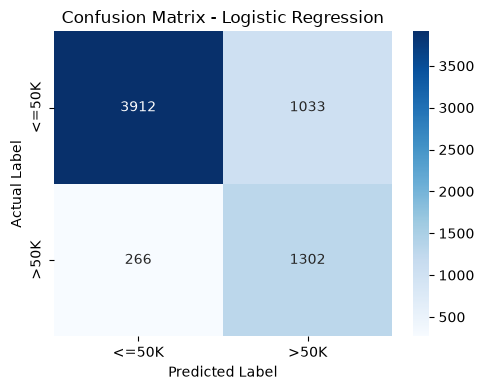


KNN Classifier
              precision    recall  f1-score   support

       <=50K       0.92      0.78      0.84      4945
        >50K       0.53      0.79      0.64      1568

    accuracy                           0.78      6513
   macro avg       0.73      0.79      0.74      6513
weighted avg       0.83      0.78      0.79      6513



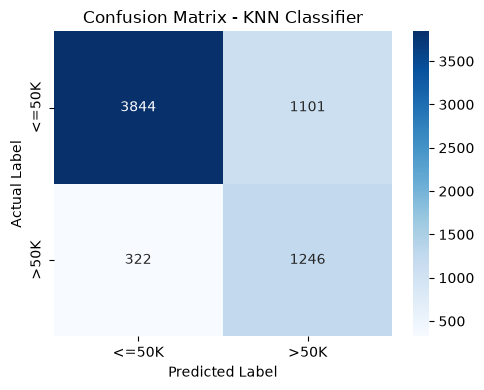


Naive Bayes
              precision    recall  f1-score   support

       <=50K       0.95      0.39      0.55      4945
        >50K       0.33      0.94      0.48      1568

    accuracy                           0.52      6513
   macro avg       0.64      0.66      0.52      6513
weighted avg       0.80      0.52      0.54      6513



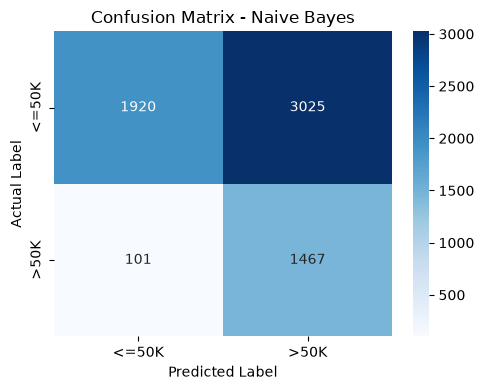

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results)


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        output_dict=True,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Confusion Matrix": str(cm.tolist()),
        "Classification Report": (
            f"<=50K: P={report['<=50K']['precision']:.3f}, "
            f"R={report['<=50K']['recall']:.3f}, "
            f"F1={report['<=50K']['f1-score']:.3f}\n"
            f">50K: P={report['>50K']['precision']:.3f}, "
            f"R={report['>50K']['recall']:.3f}, "
            f"F1={report['>50K']['f1-score']:.3f}"
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score,Confusion Matrix,Classification Report
0,Logistic Regression,0.801,0.558,0.830,0.667,"[[3912, 1033], [266, 1302]]","<=50K: P=0.936, R=0.791, F1=0.858\n>50K: P=0.5..."
1,KNN Classifier,0.782,0.531,0.795,0.637,"[[3844, 1101], [322, 1246]]","<=50K: P=0.923, R=0.777, F1=0.844\n>50K: P=0.5..."
2,Naive Bayes,0.520,0.327,0.936,0.484,"[[1920, 3025], [101, 1467]]","<=50K: P=0.950, R=0.388, F1=0.551\n>50K: P=0.3..."


Decision Tree classification

In [ ]:
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0,1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

In [46]:
from sklearn.tree import DecisionTreeClassifier,plot_tree


In [48]:
model = DecisionTreeClassifier(
        criterion='gini',
        random_state=100,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        min_impurity_decrease=0.01,
        ccp_alpha=0.01
    )

In [49]:
from sklearn.metrics import accuracy_score

In [50]:
# Train model
model.fit(X_train, y_train)

# Predictions
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ================= Metrics =================
Acc_Train = accuracy_score(y_train, y_pred_train)
Acc_Test  = accuracy_score(y_test, y_pred_test)

print(
    Acc_Train, 
    Acc_Test,  
)

0.8437883906633906 0.8436972209427299


In [53]:
[str(c) for c in model.classes_]

['0', '1']

Decision Tree - Plotting the tree


IndexError: list index out of range

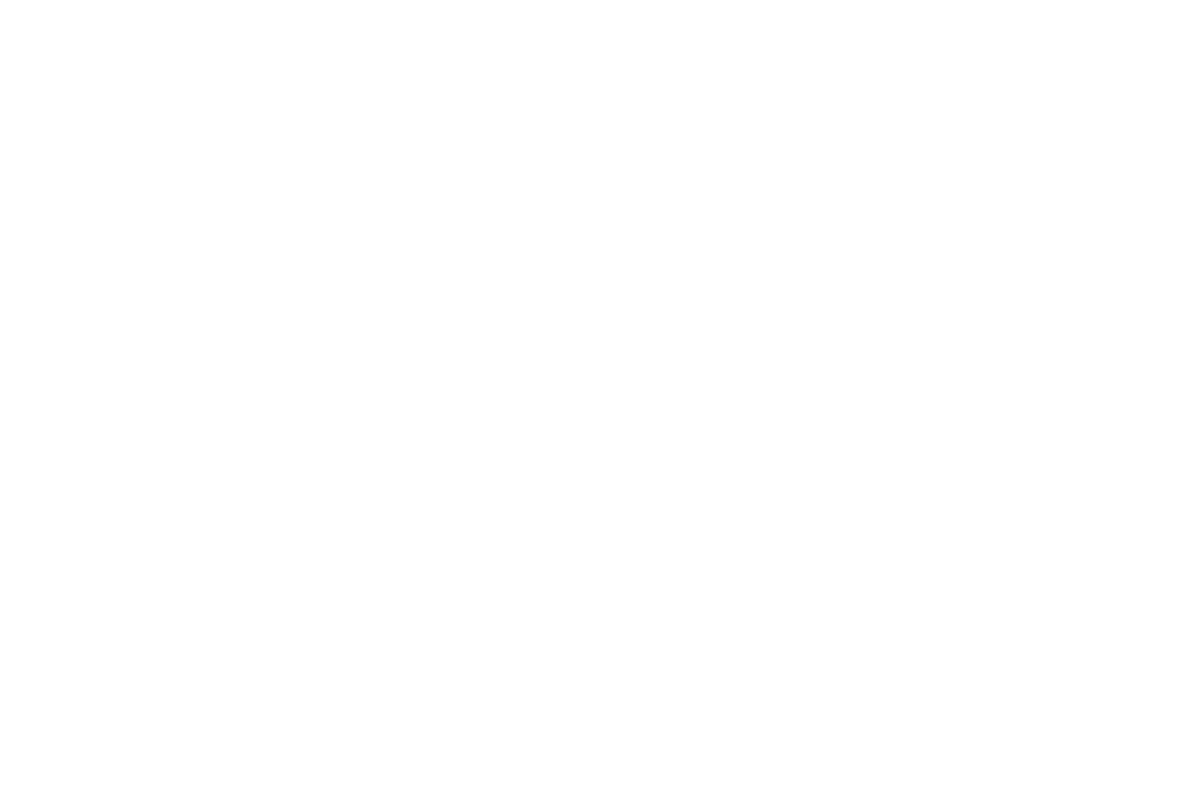

In [51]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# Apply All Classification Models
# =========================
# This section applies the complete model set from Classification Models.ipynb
# to the prepared X_train, X_test, y_train, y_test variables.

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier,
    VotingClassifier, StackingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)
from sklearn.base import clone

classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVC": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42),
    "LightGBM": LGBMClassifier(random_state=42)
}

classification_results = []
classification_fitted = {}

for name, model in classification_models.items():
    print(f"\n{'='*60}\n{name}\n{'='*60}")
    model.fit(X_train, y_train)
    classification_fitted[name] = model

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan,
        "PR AUC": average_precision_score(y_test, y_prob) if y_prob is not None else np.nan
    })

    print(classification_report(y_test, y_pred, zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

classification_results_df = pd.DataFrame(classification_results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)
classification_results_df.round(4)


In [ ]:
# =========================
# Voting Classifier
# =========================
voting_model = VotingClassifier(
    estimators=[
        ("lr", clone(classification_models["Logistic Regression"])),
        ("rf", clone(classification_models["Random Forest"])),
        ("nb", clone(classification_models["Naive Bayes"])),
        ("xgb", clone(classification_models["XGBoost"]))
    ],
    voting="soft"
)
voting_model.fit(X_train, y_train)
y_pred = voting_model.predict(X_test)
y_prob = voting_model.predict_proba(X_test)[:, 1]

voting_result = {
    "Model": "Voting Classifier",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR AUC": average_precision_score(y_test, y_prob)
}
classification_results_df = pd.concat([classification_results_df, pd.DataFrame([voting_result])], ignore_index=True)
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

classification_results_df.sort_values("F1 Score", ascending=False).reset_index(drop=True).round(4)


In [ ]:
# =========================
# Stacking Classifier
# =========================
stacking_model = StackingClassifier(
    estimators=[
        ("lr", clone(classification_models["Logistic Regression"])),
        ("rf", clone(classification_models["Random Forest"])),
        ("nb", clone(classification_models["Naive Bayes"])),
        ("lgbm", clone(classification_models["LightGBM"]))
    ],
    final_estimator=XGBClassifier(n_estimators=100, random_state=42, eval_metric="logloss"),
    stack_method="predict_proba",
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)
y_pred = stacking_model.predict(X_test)
y_prob = stacking_model.predict_proba(X_test)[:, 1]

stacking_result = {
    "Model": "Stacking Classifier",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR AUC": average_precision_score(y_test, y_prob)
}
classification_results_df = pd.concat([classification_results_df, pd.DataFrame([stacking_result])], ignore_index=True)
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

classification_results_df = classification_results_df.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)
classification_results_df.round(4)
